# Przygotowanie danych

Projekt: **Wykrywanie Anomalii i Nadużyć w Transakcjach Bankowych za Pomocą Autoenkodera**.

Wynikiem jest plik `data/processed/splits.npz` (+ dopasowany scaler), z którego korzystają kolejne fazy projektu.

In [116]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

DATA_PATH = Path("creditcard.pkl")
OUT_DIR = Path("processed")
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

## Wczytanie zbioru i analiza klas

Wykorzystany zbiór: Credit Card Fraud Detection 
Źródło: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
Kolumny:
- `Time` - sekundy od pierwszej transakcji w zbiorze,
- `V1`–`V28` - składowe PCA,
- `Amount` - kwota transakcji,
- `Class` - 0 = transakcja prawidłowa, 1 = fraud.

In [117]:
df = pd.read_pickle(DATA_PATH)
print(f"Kształt: {df.shape}")
df.head()

Kształt: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [118]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

Wszystkie kolumny są danymi numerycznymi poza zmienną zależną, która jest zmienną kategoryczną.

In [119]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


### Rozkład klas

In [120]:
class_counts = df["Class"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "liczba": class_counts,
    "udział [%]": (class_counts / len(df) * 100).round(3),
})
class_summary.index = class_summary.index.map({0: "0 - prawidłowa", 1: "1 - fraud"})
class_summary

,liczba,udział [%]
Class,,
0 - prawidłowa,284315,99.827
1 - fraud,492,0.173


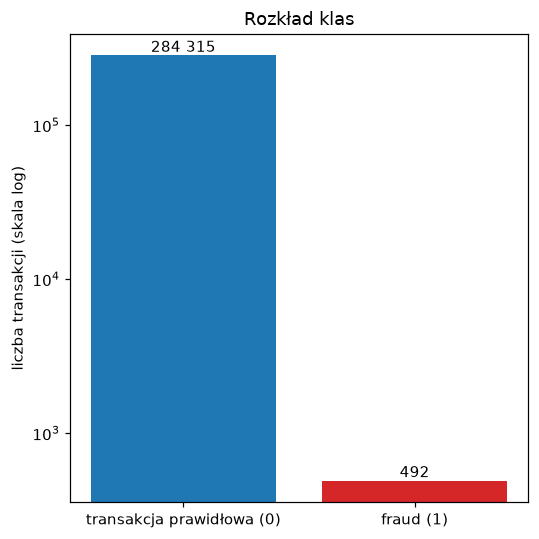

In [121]:
fig, ax = plt.subplots(figsize=(5, 5))
bars = ax.bar(["transakcja prawidłowa (0)", "fraud (1)"], class_counts.values, color=["tab:blue", "tab:red"])
ax.set_yscale("log")
ax.set_ylabel("liczba transakcji (skala log)")
ax.set_title("Rozkład klas")
ax.yaxis.set_minor_locator(plt.NullLocator())
ax.bar_label(bars, labels=[f"{v:,}".replace(",", " ") for v in class_counts.values])
plt.tight_layout()
plt.show()

Na wykresie można zaobserwować silne niezbalansowanie, fałszywe tranzakcje stanowią około 0,17% wszystkich tranzakcji. Z tego powodu miarami jakości modelu będą: Recall, FPR, Precision, F1 oraz macierz pomyłek. Przy wyborze accuracy jako miary jakości model który zagduje klasę większościową mogłby uzyskać wynik na poziomie około 99,83%, co nie odzwierciedlałoby jego zdolności predykcyjnych. Dodatkowo uzasadnia to wybór autoencodera do wykrywania odchyleń od normy, ponieważ w środowisku produkcyjnym nie wiadomo jak wyglada fałszywa transakcja, natomiast wiadomo jak wyglada poprawna transakcja.

### Rozkład kwot i czasu w podziale na klasy

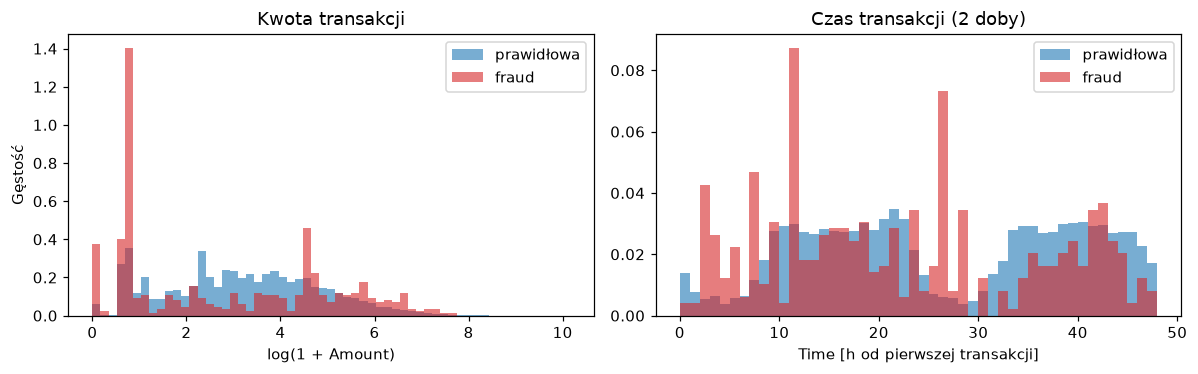

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [122]:
normal, fraud = df[df["Class"] == 0], df[df["Class"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.linspace(0, np.log1p(df["Amount"].max()), 60)
axes[0].hist(np.log1p(normal["Amount"]), bins=bins, density=True, alpha=0.6, label="prawidłowa")
axes[0].hist(np.log1p(fraud["Amount"]), bins=bins, density=True, alpha=0.6, label="fraud", color="tab:red")
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_ylabel("Gęstość")
axes[0].set_title("Kwota transakcji")
axes[0].legend()

bins_t = np.linspace(0, df["Time"].max() / 3600, 49)
axes[1].hist(normal["Time"] / 3600, bins=bins_t, density=True, alpha=0.6, label="prawidłowa")
axes[1].hist(fraud["Time"] / 3600, bins=bins_t, density=True, alpha=0.6, label="fraud", color="tab:red")
axes[1].set_xlabel("Time [h od pierwszej transakcji]")
axes[1].set_title("Czas transakcji (2 doby)")
axes[1].legend()
plt.tight_layout()
plt.show()

df.groupby("Class")["Amount"].describe()

Zmienna `Amount` jest prawostronnie skośna, przez co aby ustabilizowac i lepiej zaprezentować dane zastosowano transformację logarytmiczną $log(x + 1)$

Zmienna `Time` pokazuje pokazuje, ze w pewnych godzinach w cyklu dobowym, następuje wzmożenie tranzakcji fałszywych. Zmienną tą zatem warto wykorzystać przy trenowaniu modelu, jednak należy ją do tego przystosować, żeby odpowiednio odzwierciedlała upływ czasu.

## Czyszczenie zbioru

### Braki danych

In [123]:
missing = df.isna().sum()
print(f"Braki: {missing.sum()}")
missing[missing > 0]

Braki: 0


Series([], dtype: int64)

Zbiór nie ma żadnych braków, a więc żadna operacja wypełniania/usuwania pustych danych nie została wykonana.

### Duplikaty

In [124]:
dup_mask = df.duplicated(keep="first")
n_dup = dup_mask.sum()
print(f"Zduplikowane wiersze (kopie poza pierwszym wystąpieniem): {n_dup} ({n_dup / len(df):.2%})")
print("w tym w klasie:")
print(df.loc[dup_mask, "Class"].value_counts().rename(index={0: "prawidłowa", 1: "fraud"}).to_string())

features_all = df.columns.drop("Class")
conflicting = df[df.duplicated(subset=features_all, keep=False)].groupby(list(features_all))["Class"].nunique()
print(f"\nGrupy identycznych cech z różnymi etykietami: {(conflicting > 1).sum()}")

Zduplikowane wiersze (kopie poza pierwszym wystąpieniem): 1081 (0.38%)
w tym w klasie:
Class
prawidłowa    1062
fraud           19

Grupy identycznych cech z różnymi etykietami: 0


Po przyjrzeniu się rekordom, za duplikat uznajemy wiersz, który ma wszystkie dane w kolumnach takie same, ponieważ jest mało prawdopodobym, żeby została wykonana taka sama transakcja w tej samej sekundzie. Duplikaty zostają usunięte poza ich pierwszym wystąpieniem, ponieważ nadal niesie ono informacje na temat poprawności tranzakcji.

Dodatkowo sprawdzono czy istnieją rekordy, których wszystkie wartości są takie same poza klasyfikacją. Takich rekordów nie znaleziono, natomiast gdyby takowe wystąpiły, należałoby każde takie wystąpienie usunąć. Pozostawienie takich danych, błędnie wytrenować model, gdyż jedna transakcja miałaby dwa przypisania.

In [125]:
df_clean = df.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Przed: {len(df)} - po usunięciu duplikatów: {len(df_clean)}")
df_clean["Class"].value_counts().rename(index={0: "prawidłowa", 1: "fraud"})

Przed: 284807 - po usunięciu duplikatów: 283726


Class
prawidłowa    283253
fraud            473
Name: count, dtype: int64

### Zmienna Time

Wartość tej zmiennej w takiej postaci nie daje żadnej sensownej informacji, ponieważ w produkcyjnym środowisku nie będzie takiego odniesienia, natomiast tą zmienną można wykorzystać do określenia pewnej pory w której częstotliwość fałszywych tranzakcji się wzmaża.

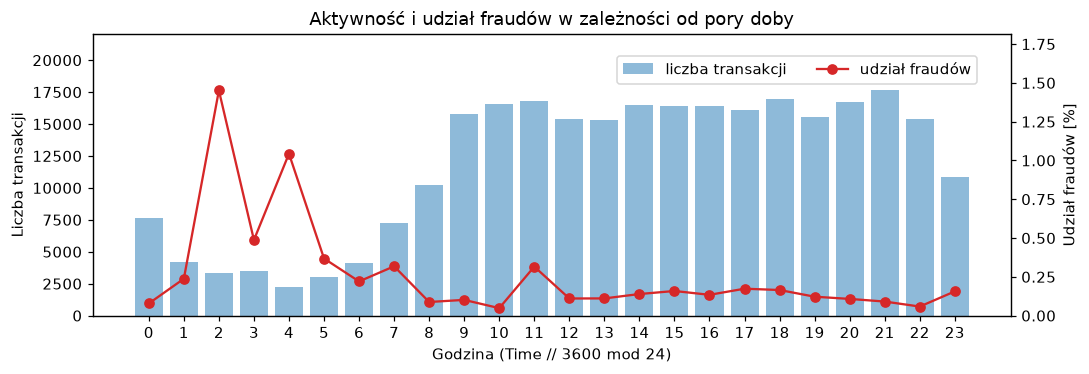

In [126]:
hour = (df_clean["Time"] // 3600) % 24
by_hour = df_clean.groupby(hour)["Class"].agg(transakcje="count", fraud="sum", udzial_fraud="mean")

fig, ax1 = plt.subplots(figsize=(10, 3.5))
ax1.bar(by_hour.index, by_hour["transakcje"], color="tab:blue", alpha=0.5, label="liczba transakcji")
ax1.set_xlabel("Godzina (Time // 3600 mod 24)")
ax1.set_ylabel("Liczba transakcji")
ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour["udzial_fraud"] * 100, color="tab:red", marker="o", label="udział fraudów")
ax2.set_ylabel("Udział fraudów [%]")
ax1.set_ylim(0, by_hour["transakcje"].max() * 1.25)
ax2.set_ylim(0, by_hour["udzial_fraud"].max() * 100 * 1.25)
ax1.set_xticks(range(24))
ax1.set_title("Aktywność i udział fraudów w zależności od pory doby")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.86), ncol=2)
plt.tight_layout()
plt.show()

Zmienna Time zostaje przetransformowana na wartości sinus oraz cosinus, zeby zachować ciągłośc w przejściu dobowym z 23:59 na 00:00. Nie wiadomo jakie jest przesunięcie godzinowe, natomiast dla modelu liczy się tylko cykl.

$$\text{hour} = \frac{\text{Time} \bmod 86400}{3600}, \qquad
\text{hour\_sin} = \sin\left(\frac{2\pi\,\text{hour}}{24}\right), \qquad
\text{hour\_cos} = \cos\left(\frac{2\pi\,\text{hour}}{24}\right)$$

In [127]:
hour_float = (df_clean["Time"] % 86400) / 3600
df_clean["hour_sin"] = np.sin(2 * np.pi * hour_float / 24)
df_clean["hour_cos"] = np.cos(2 * np.pi * hour_float / 24)

df_clean["Amount"] = np.log1p(df_clean["Amount"])

df_clean = df_clean.drop(columns="Time")

FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount", "hour_sin", "hour_cos"]
TARGET = "Class"
print(f"Liczba cech: {len(FEATURES)}")
df_clean[FEATURES + [TARGET]].head()

Liczba cech: 31


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,hour_sin,hour_cos,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,5.014760,0.000000,1.0,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,1.305626,0.000000,1.0,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,5.939276,0.000073,1.0,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,4.824306,0.000073,1.0,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,4.262539,0.000145,1.0,0


## Przygotowanie danych do modelowania

### Strategia podziału

Autoenkoder trenujemy w trybie one-class, więc:

| zbiór | transakcje prawidłowe | fraudy | zastosowanie |
|---|---|---|---|
| **train** | 70% | 0 | trening autoenkodera, dopasowanie scalera |
| **val** | 15% | 50% | monitorowanie treningu, wybór progu MSE, strojenie hiperparametrów |
| **test** | 15% | 50% | jednorazowa, niezależna ocena końcowa |

In [128]:
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

normal_idx = df_clean.index[df_clean[TARGET] == 0].to_numpy()
fraud_idx = df_clean.index[df_clean[TARGET] == 1].to_numpy()

normal_train_idx, normal_rest_idx = train_test_split(
    normal_idx, train_size=TRAIN_FRAC, random_state=SEED, shuffle=True
)
normal_val_idx, normal_test_idx = train_test_split(
    normal_rest_idx, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), random_state=SEED, shuffle=True
)

fraud_val_idx, fraud_test_idx = train_test_split(
    fraud_idx, test_size=0.5, random_state=SEED, shuffle=True
)

rng = np.random.default_rng(SEED)
train_idx = rng.permutation(normal_train_idx)
val_idx = rng.permutation(np.concatenate([normal_val_idx, fraud_val_idx]))
test_idx = rng.permutation(np.concatenate([normal_test_idx, fraud_test_idx]))

split_summary = pd.DataFrame.from_dict({
    split: {
        "prawidłowe": int((df_clean.loc[idx, TARGET] == 0).sum()),
        "fraud": int((df_clean.loc[idx, TARGET] == 1).sum()),
        "razem": len(idx),
        "udział fraud [%]": round(df_clean.loc[idx, TARGET].mean() * 100, 3),
    }
    for split, idx in {"train": train_idx, "val": val_idx, "test": test_idx}.items()
}, orient="index")
split_summary

,prawidłowe,fraud,razem,udział fraud [%]
train,198277,0,198277,0.000
val,42488,236,42724,0.552
test,42488,237,42725,0.555


### Skalowanie cech

Dane zostają przeskalowane na zbiorze treningowym, to samo sie tyczy walidacyjnego oraz testowego, aby uniknąć wycieku danych.

In [129]:
X_train_raw = df_clean.loc[train_idx, FEATURES].to_numpy(dtype=np.float32)
X_val_raw = df_clean.loc[val_idx, FEATURES].to_numpy(dtype=np.float32)
X_test_raw = df_clean.loc[test_idx, FEATURES].to_numpy(dtype=np.float32)

y_train = df_clean.loc[train_idx, TARGET].to_numpy(dtype=np.int64)
y_val = df_clean.loc[val_idx, TARGET].to_numpy(dtype=np.int64)
y_test = df_clean.loc[test_idx, TARGET].to_numpy(dtype=np.int64)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)   # fit tylko na train
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

pd.DataFrame({
    "train mean": X_train.mean(axis=0), "train std": X_train.std(axis=0),
    "val mean": X_val.mean(axis=0), "test mean": X_test.mean(axis=0),
}, index=FEATURES).round(3).T

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,hour_sin,hour_cos
train mean,-0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000,0.000,-0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000,0.000,-0.000,0.000,0.000
train std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
val mean,-0.017,0.006,-0.028,0.024,-0.002,-0.011,-0.024,0.003,-0.016,-0.029,0.021,-0.027,0.001,-0.040,-0.006,-0.031,-0.054,-0.026,0.010,-0.004,0.007,0.005,0.002,0.003,-0.003,0.011,0.004,0.016,-0.003,0.002,-0.002
test mean,-0.006,0.013,-0.020,0.023,-0.007,0.001,-0.029,0.005,-0.012,-0.030,0.019,-0.042,-0.004,-0.046,-0.010,-0.027,-0.045,-0.015,0.006,0.003,0.010,0.000,0.008,0.002,0.000,0.005,-0.011,0.009,-0.009,0.002,-0.000


Na zbiorze treningowym cechy mają średnią 0 i odchylenie 1. W val/test średnie są bliskie 0, ale nie równe zero co wskazuje na to ze sa zblizone do danych treningowych ale nie identyczne. Największe odchylenia wynikają z zawartości tranzakcji fałszywych.

### Zapis wyników

- `data/processed/splits.npz` - macierze `X_*` (przeskalowane, `float32`), etykiety `y_*`, indeksy `idx_*`, lista cech.
- `data/processed/scaler.joblib` - dopasowany `StandardScaler`.

Kod do wczytania wyczyszczonych zbiorów:
```python
data = np.load("data/processed/splits.npz", allow_pickle=False)
X_train, X_val, y_val, X_test, y_test = (data[k] for k in ["X_train", "X_val", "y_val", "X_test", "y_test"])
```

In [130]:
np.savez_compressed(
    OUT_DIR / "splits.npz",
    X_train=X_train, y_train=y_train, idx_train=train_idx,
    X_val=X_val, y_val=y_val, idx_val=val_idx,
    X_test=X_test, y_test=y_test, idx_test=test_idx,
    feature_names=np.array(FEATURES),
)
joblib.dump(scaler, OUT_DIR / "scaler.joblib")

for f in sorted(OUT_DIR.iterdir()):
    print(f"{f}  ({f.stat().st_size / 1e6:.1f} MB)")

processed\scaler.joblib  (0.0 MB)
processed\splits.npz  (33.1 MB)


## Podsumowanie

- zbiór zawiera 284 807 transakcji, 492 fraudy jest więc silnie niezbalansowany, a accuracy nie dałoby żadnej informacji jako miara.
- nie ma braków danych, usunięto 1 081 zduplikowanych wierszy, aby uniknąć wycieku między zbiorami.
- zmienna Time usunięta w surowej postaci, zastąpiona cyklicznym kodowaniem pory doby.
- zastosowano transformację `log1p` na zmienne Amount.
- wykorzystano podział train = 70% prawidłowych, 0 fraudów; val i test = po 15% prawidłowych i po 50% fraudów.
- dane przeskalowano za pomocą zbioru treningowego.